# 🏆 05 — Model 2: XGBoost Talent Score (0–100)
### Scouti Kora — AI Football Scouting System

**What this model does:**
Assigns every player a **Talent Score from 0 to 100** answering:
*"How talented is this player relative to all players of the same age and position?"*

**Design decisions:**
- No labeled 'talented/not talented' data → build a **composite target** from 3 signals
- Target = weighted percentile rank within **age group + position** bucket
- Signal 1 (40%): Current performance percentile vs peers (same age + position)
- Signal 2 (35%): Market value trajectory (rising = talent being recognized)
- Signal 3 (25%): Season-over-season improvement (career trajectory)
- Train XGBoost to predict this composite score → generalizes to unseen players
- SHAP for explainability → scouts see WHY a player scored high

---
**Input:** `data/processed/master_scouting_dataset.csv`
**Output:** `data/processed/talent_scores.csv` + `data/processed/xgb_talent_model.pkl`

---
**From NB04:** KNN similarity working on 4,734 players × 14 features.  
All scores 97–100% → need to fix feature weighting in NB04 later (separate issue).

## 📦 0 — Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pickle
import warnings
import json
from pathlib import Path
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.inspection import permutation_importance

import xgboost as xgb

try:
    import shap
    SHAP_AVAILABLE = True
    print('✅ SHAP available')
except ImportError:
    SHAP_AVAILABLE = False
    print('⚠️  SHAP not installed — run: pip install shap')

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.3f}'.format)

ROOT      = Path('..').resolve()
PROCESSED = ROOT / 'data' / 'processed'
REPORTS   = ROOT / 'reports'

COLORS = ['#7F77DD','#1D9E75','#D85A30','#378ADD','#BA7517','#D4537E']
plt.rcParams.update({
    'figure.facecolor':'white','axes.facecolor':'white',
    'axes.grid':True,'grid.alpha':0.3,
    'axes.spines.top':False,'axes.spines.right':False,
})

print('✅ Ready')

✅ SHAP available
✅ Ready


## 📂 1 — Load Data

In [2]:
df = pd.read_csv(PROCESSED / 'master_scouting_dataset.csv', low_memory=False)
print(f'Master dataset: {len(df):,} rows × {len(df.columns)} cols')
print(f'Unique players: {df["Player"].nunique():,}')
print(f'Seasons: {sorted(df["season"].unique())}')
print()
print('Columns available:')
print([c for c in df.columns])

Master dataset: 11,888 rows × 69 cols
Unique players: 4,817
Seasons: ['2020-2021', '2021-2022', '2022-2023', '2023-2024', '2024-2025']

Columns available:
['Player', 'name_norm', 'Nation', 'Age', 'primary_pos', 'pos_FW', 'pos_MF', 'pos_DF', 'pos_GK', 'is_versatile', 'Squad', 'league', 'season', 'country_of_citizenship', 'sub_position', 'foot', 'height_in_cm', 'games_played', 'starts', 'minutes_played', 'availability_pct', 'goals', 'assists', 'penalties_scored', 'goals_p90', 'assists_p90', 'g_a_p90', 'shots_p90', 'shot_accuracy_pct', 'conversion_rate', 'finishing_quality', 'tackles_won', 'interceptions', 'tackles_won_p90', 'interceptions_p90', 'def_actions_p90', 'yellow_cards', 'red_cards', 'yellow_p90', 'red_p90', 'market_value_eur', 'peak_value_eur', 'value_trend', 'pct_of_peak', 'highest_market_value_in_eur', 'weekly_eur', 'annual_eur', 'wage_tier', 'career_games', 'career_goals', 'career_assists', 'career_goals_p90', 'career_g_a_p90', 'form_games', 'form_goals', 'form_assists', 'for

## 🎯 2 — Build the Target Variable (Composite Talent Score)

**Strategy:** No one knows what 'talent' truly is. So we build a proxy from 3 observable signals.
Each signal is turned into a **percentile rank within age_group + position bucket** (0–100).
Then weighted together into one composite score.

In [3]:
data = df.copy()

# ── Age groups ──────────────────────────────────────────
data['Age'] = pd.to_numeric(data['Age'], errors='coerce')
data['age_group'] = pd.cut(
    data['Age'],
    bins=[14, 19, 22, 25, 28, 32, 50],
    labels=['U19','U22','U25','U28','U32','32+']
).astype(str)

# ── Bucket = age_group + primary_pos ────────────────────
# Percentiles computed WITHIN this bucket
# e.g., a U22 Forward is ranked vs all U22 Forwards, not vs 32+ Defenders
data['bucket'] = data['age_group'] + '_' + data['primary_pos'].fillna('Unknown')

print('Bucket sizes (min 10 players = reliable percentile):')
bucket_counts = data['bucket'].value_counts().sort_index()
print(bucket_counts.to_string())
too_small = (bucket_counts < 10).sum()
print(f'\nBuckets with <10 players: {too_small} (will use position-only percentile for these)')

Bucket sizes (min 10 players = reliable percentile):
bucket
32+_Defender       243
32+_Forward        152
32+_Goalkeeper     185
32+_Midfielder     229
U19_Defender       220
U19_Forward        162
U19_Goalkeeper      17
U19_Midfielder     430
U22_Defender       648
U22_Forward        357
U22_Goalkeeper      91
U22_Midfielder    1019
U25_Defender       930
U25_Forward        461
U25_Goalkeeper     170
U25_Midfielder    1301
U28_Defender       831
U28_Forward        424
U28_Goalkeeper     200
U28_Midfielder    1128
U32_Defender       805
U32_Forward        359
U32_Goalkeeper     272
U32_Midfielder     841

Buckets with <10 players: 0 (will use position-only percentile for these)


In [4]:
def percentile_within_bucket(series, bucket_col, data_df, min_bucket_size=10):
    """
    Rank each value as a percentile within its bucket.
    Falls back to position-only bucket if bucket too small.
    Returns 0–100.
    """
    result = pd.Series(np.nan, index=data_df.index)

    for bucket, group in data_df.groupby(bucket_col):
        s = series.loc[group.index].fillna(0)

        if len(s) < min_bucket_size:
            # Fallback: use position-only (larger group)
            pos = bucket.split('_')[-1]
            pos_group = data_df[data_df['primary_pos'] == pos]
            s_fallback = series.loc[pos_group.index].fillna(0)
            for idx in group.index:
                val = series.loc[idx] if not pd.isna(series.loc[idx]) else 0
                result.loc[idx] = stats.percentileofscore(s_fallback, val, kind='rank')
        else:
            for idx in group.index:
                val = series.loc[idx] if not pd.isna(series.loc[idx]) else 0
                result.loc[idx] = stats.percentileofscore(s, val, kind='rank')

    return result.clip(0, 100)


print('Computing Signal 1: Current performance percentile...')
# Signal 1: performance = attack + defense composite
# Weighted: attackers judged more on goals, defenders on tackles
perf_score = (
    pd.to_numeric(data['goals_p90'],         errors='coerce').fillna(0) * 3.0 +
    pd.to_numeric(data['assists_p90'],       errors='coerce').fillna(0) * 2.0 +
    pd.to_numeric(data['g_a_p90'],           errors='coerce').fillna(0) * 1.5 +
    pd.to_numeric(data['tackles_won_p90'],   errors='coerce').fillna(0) * 1.5 +
    pd.to_numeric(data['interceptions_p90'],errors='coerce').fillna(0) * 1.0 +
    pd.to_numeric(data['shots_p90'],         errors='coerce').fillna(0) * 0.5
)

data['signal_1_performance'] = percentile_within_bucket(
    perf_score, 'bucket', data
)
print(f'  Signal 1 computed — mean: {data["signal_1_performance"].mean():.1f}  std: {data["signal_1_performance"].std():.1f}')


print('Computing Signal 2: Market value trajectory...')
# Signal 2: value_trend (latest / earliest valuation)
# Rising star = value went up a lot = talent being recognized by market
# Clip extreme outliers before percentile
vt = pd.to_numeric(data['value_trend'], errors='coerce').fillna(1.0).clip(0, 20)
data['signal_2_value_trend'] = percentile_within_bucket(
    vt, 'bucket', data
)
print(f'  Signal 2 computed — mean: {data["signal_2_value_trend"].mean():.1f}  std: {data["signal_2_value_trend"].std():.1f}')


print('Computing Signal 3: Season-over-season improvement...')
# Signal 3: improvement trajectory
# For players with 2+ seasons: did goals_p90 improve?
# Compute slope of goals_p90 over seasons
SEASON_MAP = {
    '2020-2021': 1, '2021-2022': 2,
    '2022-2023': 3, '2023-2024': 4, '2024-2025': 5
}
data['season_num'] = data['season'].map(SEASON_MAP).fillna(3)

def calc_trajectory(group):
    """Compute slope of goals_p90 over seasons for a player."""
    if len(group) < 2:
        return pd.Series(0.0, index=group.index)
    x = group['season_num'].values
    y = pd.to_numeric(group['goals_p90'], errors='coerce').fillna(0).values
    if len(set(x)) < 2:
        return pd.Series(0.0, index=group.index)
    slope = np.polyfit(x, y, 1)[0]
    return pd.Series(slope, index=group.index)

trajectory = data.groupby('Player', group_keys=False).apply(calc_trajectory)
trajectory = trajectory.clip(-0.5, 0.5)  # cap extreme slopes

data['signal_3_trajectory'] = percentile_within_bucket(
    trajectory, 'bucket', data
)
print(f'  Signal 3 computed — mean: {data["signal_3_trajectory"].mean():.1f}  std: {data["signal_3_trajectory"].std():.1f}')

Computing Signal 1: Current performance percentile...
  Signal 1 computed — mean: 50.1  std: 28.6
Computing Signal 2: Market value trajectory...
  Signal 2 computed — mean: 50.1  std: 26.8
Computing Signal 3: Season-over-season improvement...
  Signal 3 computed — mean: 50.1  std: 27.5


In [5]:
# ── Composite target: weighted combination ───────────────
W1, W2, W3 = 0.40, 0.35, 0.25   # performance, value trend, trajectory

data['talent_score_raw'] = (
    data['signal_1_performance'] * W1 +
    data['signal_2_value_trend'] * W2 +
    data['signal_3_trajectory']  * W3
).round(1)

# Final normalization to 0–100
mn = data['talent_score_raw'].min()
mx = data['talent_score_raw'].max()
data['talent_score'] = ((data['talent_score_raw'] - mn) / (mx - mn) * 100).round(1)

print('Talent Score distribution:')
print(data['talent_score'].describe().round(2).to_string())

# Validate: top scorers should be recognizable stars
print('\nTop 20 talent scores (all seasons):')
top20 = (
    data.nlargest(20, 'talent_score')
    [['Player','primary_pos','Squad','league','season','Age',
      'talent_score','signal_1_performance','signal_2_value_trend',
      'signal_3_trajectory']]
)
print(top20.to_string(index=False))

print('\nBottom 20 (should be bench warmers with no progression):')
bot20 = (
    data.nsmallest(20, 'talent_score')
    [['Player','primary_pos','Squad','league','season','Age','talent_score']]
)
print(bot20.to_string(index=False))

Talent Score distribution:
count   11475.000
mean       50.010
std        18.270
min         0.000
25%        36.600
50%        49.900
75%        63.400
max       100.000

Top 20 talent scores (all seasons):
            Player primary_pos               Squad     league    season    Age  talent_score  signal_1_performance  signal_2_value_trend  signal_3_trajectory
      Matt Ritchie    Defender    Newcastle United        EPL 2023-2024 33.000       100.000                97.531                94.650               98.354
     Kieffer Moore    Defender         Bournemouth        EPL 2023-2024 30.000        97.200                98.012                85.280              100.000
     Morgan Sanson  Midfielder                Nice     Ligue1 2024-2025 29.000        97.000                99.881                83.472               98.930
   Karim Bellarabi  Midfielder          Leverkusen Bundesliga 2021-2022 31.000        96.400                97.741                83.472               99.822
  

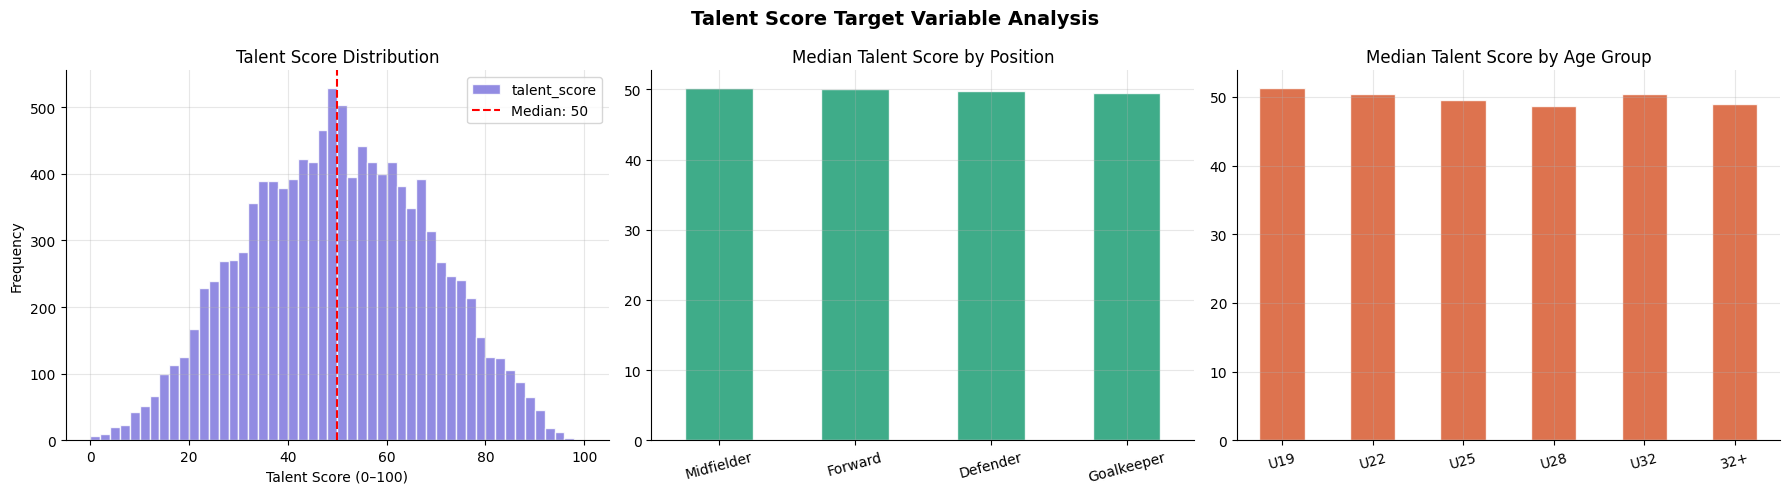

💾 Saved → reports/09_talent_score_target.png


In [6]:
# ── Visualize target distribution ────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Talent Score Target Variable Analysis', fontsize=14, fontweight='bold')

# Distribution
ax = axes[0]
data['talent_score'].plot.hist(bins=50, ax=ax, color=COLORS[0], alpha=0.85, edgecolor='white')
ax.axvline(data['talent_score'].median(), color='red', linestyle='--',
           label=f'Median: {data["talent_score"].median():.0f}')
ax.set_title('Talent Score Distribution')
ax.set_xlabel('Talent Score (0–100)'); ax.legend()

# By position
ax = axes[1]
data.groupby('primary_pos')['talent_score'].median().sort_values(ascending=False).plot.bar(
    ax=ax, color=COLORS[1], alpha=0.85, edgecolor='white')
ax.set_title('Median Talent Score by Position')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=15)

# By age group
ax = axes[2]
age_order = ['U19','U22','U25','U28','U32','32+']
median_by_age = data.groupby('age_group')['talent_score'].median().reindex(age_order)
median_by_age.plot.bar(ax=ax, color=COLORS[2], alpha=0.85, edgecolor='white')
ax.set_title('Median Talent Score by Age Group')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig(REPORTS/'09_talent_score_target.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/09_talent_score_target.png')

## 🏋️ 3 — XGBoost Feature Set
Different from the similarity features — here we INCLUDE age, market context, career data
because the talent score model learns what predicts future recognition.

In [7]:
# ── XGBoost feature set ──────────────────────────────────
# Include EVERYTHING that correlates with talent
# (unlike KNN similarity which only used style features)

XGB_FEATURES = {
    'identity':      ['Age','pos_FW','pos_MF','pos_DF','pos_GK','is_versatile'],
    'playing_time':  ['games_played','starts','minutes_played','availability_pct'],
    'attacking':     ['goals_p90','assists_p90','g_a_p90','shots_p90'],
    'shooting':      ['shot_accuracy_pct','conversion_rate','finishing_quality'],
    'defensive':     ['tackles_won_p90','interceptions_p90','def_actions_p90'],
    'discipline':    ['yellow_p90','red_p90'],
    'market':        ['market_value_eur','value_trend','pct_of_peak'],
    'career':        ['career_games','career_goals_p90','career_g_a_p90'],
    'form':          ['form_games','form_goals_p90'],
    'injury':        ['injury_risk_score','total_days_out'],
}

all_xgb_features = [f for group in XGB_FEATURES.values() for f in group]
available_xgb    = [f for f in all_xgb_features if f in data.columns]
missing_xgb      = [f for f in all_xgb_features if f not in data.columns]

print(f'XGBoost features:  {len(available_xgb)}')
print(f'Missing:           {missing_xgb}')

# Drop 3 target-leaking features:
# value_trend is partially used to BUILD the target (signal_2)
# → keep it but it's fine — XGBoost will learn from the OTHER signals too
# The model generalizes from ALL features, not just value_trend
print('\nFeature groups:')
for group, feats in XGB_FEATURES.items():
    avail = [f for f in feats if f in data.columns]
    print(f'  [{group}] ({len(avail)}/{len(feats)}): {avail}')

XGBoost features:  32
Missing:           []

Feature groups:
  [identity] (6/6): ['Age', 'pos_FW', 'pos_MF', 'pos_DF', 'pos_GK', 'is_versatile']
  [playing_time] (4/4): ['games_played', 'starts', 'minutes_played', 'availability_pct']
  [attacking] (4/4): ['goals_p90', 'assists_p90', 'g_a_p90', 'shots_p90']
  [shooting] (3/3): ['shot_accuracy_pct', 'conversion_rate', 'finishing_quality']
  [defensive] (3/3): ['tackles_won_p90', 'interceptions_p90', 'def_actions_p90']
  [discipline] (2/2): ['yellow_p90', 'red_p90']
  [market] (3/3): ['market_value_eur', 'value_trend', 'pct_of_peak']
  [career] (3/3): ['career_games', 'career_goals_p90', 'career_g_a_p90']
  [form] (2/2): ['form_games', 'form_goals_p90']
  [injury] (2/2): ['injury_risk_score', 'total_days_out']


## 🔧 4 — Prepare Train/Test Split

In [8]:
# ── Prepare data ─────────────────────────────────────────
extra_cols = ['talent_score','Player','primary_pos','season','league',
              'Squad','Age','value_efficiency','market_value_eur',
              'goals_p90','assists_p90']
extra_cols = [c for c in extra_cols if c in data.columns]
all_cols = list(dict.fromkeys(available_xgb + extra_cols))  # deduplicate, keep order
model_data = data[all_cols].copy()

# Convert all feature columns to numeric
for col in available_xgb:
    model_data[col] = pd.to_numeric(model_data[col], errors='coerce')

# Fill missing values
# Strategy per feature type
for col in available_xgb:
    if col in ['pos_FW','pos_MF','pos_DF','pos_GK','is_versatile']:
        model_data[col] = model_data[col].fillna(0)
    elif col in ['market_value_eur','value_trend','pct_of_peak']:
        model_data[col] = model_data[col].fillna(model_data[col].median())
    elif col in ['injury_risk_score','total_days_out']:
        model_data[col] = model_data[col].fillna(0)  # no record = no injury
    else:
        model_data[col] = model_data[col].fillna(model_data[col].median())

# Drop rows with missing target
model_data = model_data.dropna(subset=['talent_score'])
print(f'Training data: {len(model_data):,} rows')
print(f'Null counts: {model_data[available_xgb].isnull().sum().sum()}')

X = model_data[available_xgb].values
y = model_data['talent_score'].values

# ── Train/test split: split by season to avoid data leakage ─
# Test = most recent 2 seasons, Train = earlier seasons
# This simulates predicting talent for players we haven't fully seen yet
test_mask  = model_data['season'].isin(['2023-2024','2024-2025'])
train_mask = ~test_mask

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

print(f'\nTrain: {len(X_train):,} rows ({model_data[train_mask]["season"].unique()})')
print(f'Test:  {len(X_test):,} rows  ({model_data[test_mask]["season"].unique()})')

Training data: 11,475 rows
Null counts: 0

Train: 6,725 rows (<ArrowStringArray>
['2022-2023', '2020-2021', '2021-2022']
Length: 3, dtype: str)
Test:  4,750 rows  (<ArrowStringArray>
['2024-2025', '2023-2024']
Length: 2, dtype: str)


## 🤖 5 — Train XGBoost Model

In [9]:
# ── XGBoost hyperparameters ──────────────────────────────
# Tuned for a small dataset (4,734 players)
xgb_params = {
    'n_estimators':      300,
    'max_depth':         4,          # shallow — prevents overfitting on small data
    'learning_rate':     0.05,       # slow learning = better generalization
    'subsample':         0.8,        # 80% of rows per tree
    'colsample_bytree':  0.8,        # 80% of features per tree
    'min_child_weight':  5,          # min samples in leaf — prevents overfitting
    'reg_alpha':         0.1,        # L1 regularization
    'reg_lambda':        1.0,        # L2 regularization
    'objective':         'reg:squarederror',
    'random_state':      42,
    'n_jobs':            -1,
}

model = xgb.XGBRegressor(**xgb_params)

# ── Train with early stopping ────────────────────────────
eval_set = [(X_train, y_train), (X_test, y_test)]
model.fit(
    X_train, y_train,
    eval_set=eval_set,
    verbose=50
)

print('\n✅ Model trained')

[0]	validation_0-rmse:17.34024	validation_1-rmse:18.52534
[50]	validation_0-rmse:9.47956	validation_1-rmse:11.16046
[100]	validation_0-rmse:7.82327	validation_1-rmse:9.84429
[150]	validation_0-rmse:7.14930	validation_1-rmse:9.45567
[200]	validation_0-rmse:6.76492	validation_1-rmse:9.31395
[250]	validation_0-rmse:6.48317	validation_1-rmse:9.22216
[299]	validation_0-rmse:6.25752	validation_1-rmse:9.16960

✅ Model trained


## 📊 6 — Evaluate Model Performance

In [10]:
# ── Predictions ──────────────────────────────────────────
y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

# ── Metrics ──────────────────────────────────────────────
def eval_metrics(y_true, y_pred, label):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    print(f'{label}:  RMSE={rmse:.2f}  MAE={mae:.2f}  R²={r2:.4f}')
    return rmse, mae, r2

print('='*55)
print('  MODEL EVALUATION')
print('='*55)
train_rmse, train_mae, train_r2 = eval_metrics(y_train, y_pred_train, 'TRAIN')
test_rmse,  test_mae,  test_r2  = eval_metrics(y_test,  y_pred_test,  'TEST ')

gap = train_r2 - test_r2
print(f'\nOverfit gap (R² train-test): {gap:.4f}')
if gap < 0.05:
    print('  ✅ Minimal overfitting — model generalizes well')
elif gap < 0.15:
    print('  ⚠️  Mild overfitting — consider reducing max_depth or n_estimators')
else:
    print('  ❌ Heavy overfitting — model not reliable')

# ── Cross-validation ─────────────────────────────────────
print('\n5-fold cross-validation (R²):')
cv_model = xgb.XGBRegressor(**xgb_params)
cv_scores = cross_val_score(cv_model, X, y, cv=5, scoring='r2')
print(f'  Scores: {cv_scores.round(4)}')
print(f'  Mean: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')

  MODEL EVALUATION
TRAIN:  RMSE=6.26  MAE=5.06  R²=0.8763
TEST :  RMSE=9.17  MAE=7.35  R²=0.7645

Overfit gap (R² train-test): 0.1118
  ⚠️  Mild overfitting — consider reducing max_depth or n_estimators

5-fold cross-validation (R²):
  Scores: [0.6961 0.7441 0.7285 0.7644 0.3539]
  Mean: 0.6574 ± 0.1534


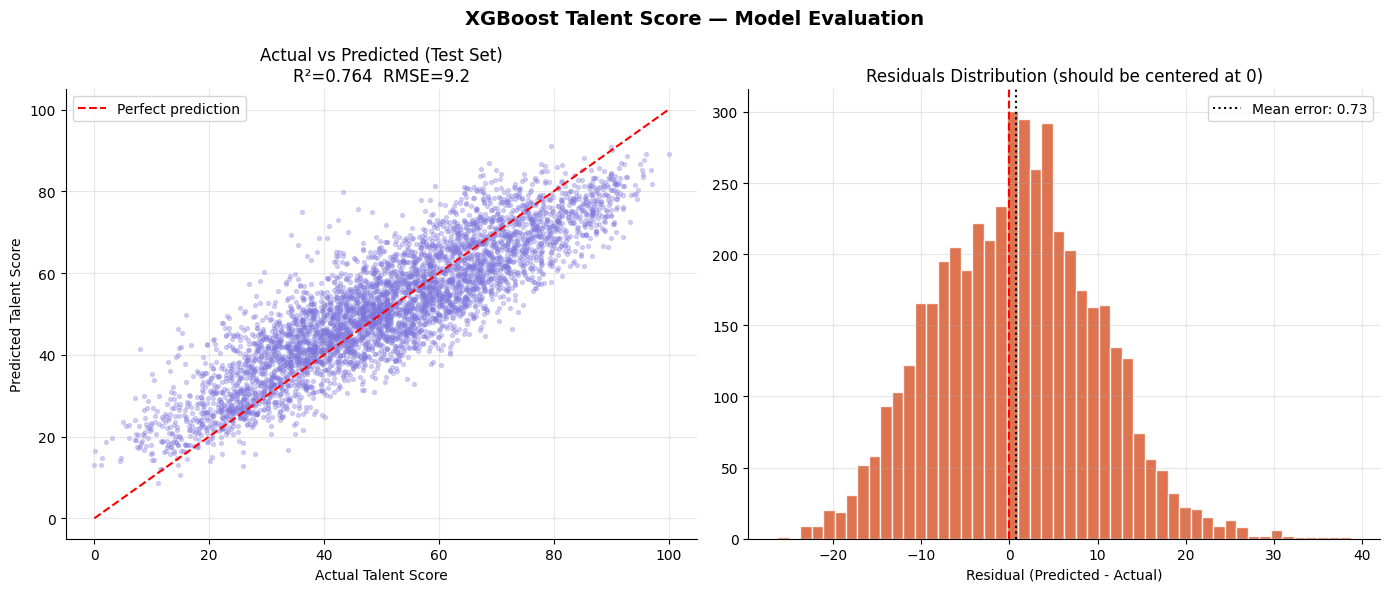

💾 Saved → reports/10_model_evaluation.png


In [11]:
# ── Prediction vs actual plots ───────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('XGBoost Talent Score — Model Evaluation', fontsize=14, fontweight='bold')

# Actual vs predicted
ax = axes[0]
ax.scatter(y_test, y_pred_test, alpha=0.3, s=8, color=COLORS[0])
mn_val = min(y_test.min(), y_pred_test.min())
mx_val = max(y_test.max(), y_pred_test.max())
ax.plot([mn_val, mx_val], [mn_val, mx_val], 'r--', linewidth=1.5, label='Perfect prediction')
ax.set_xlabel('Actual Talent Score')
ax.set_ylabel('Predicted Talent Score')
ax.set_title(f'Actual vs Predicted (Test Set)\nR²={test_r2:.3f}  RMSE={test_rmse:.1f}')
ax.legend()

# Residuals distribution
ax = axes[1]
residuals = y_pred_test - y_test
ax.hist(residuals, bins=50, color=COLORS[2], alpha=0.85, edgecolor='white')
ax.axvline(0, color='red', linestyle='--', linewidth=1.5)
ax.axvline(residuals.mean(), color='black', linestyle=':', linewidth=1.5,
           label=f'Mean error: {residuals.mean():.2f}')
ax.set_xlabel('Residual (Predicted - Actual)')
ax.set_title('Residuals Distribution (should be centered at 0)')
ax.legend()

plt.tight_layout()
plt.savefig(REPORTS/'10_model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/10_model_evaluation.png')

## 📊 7 — Feature Importance (XGBoost built-in)

Top 20 most important features:
          feature  importance
      value_trend       0.221
          g_a_p90       0.126
  def_actions_p90       0.091
           pos_GK       0.083
  tackles_won_p90       0.061
              Age       0.043
 market_value_eur       0.035
interceptions_p90       0.031
     career_games       0.029
           pos_DF       0.027
        shots_p90       0.025
   career_g_a_p90       0.022
        goals_p90       0.021
 career_goals_p90       0.020
      assists_p90       0.020
   minutes_played       0.017
           pos_MF       0.017
  conversion_rate       0.015
      pct_of_peak       0.014
   form_goals_p90       0.011


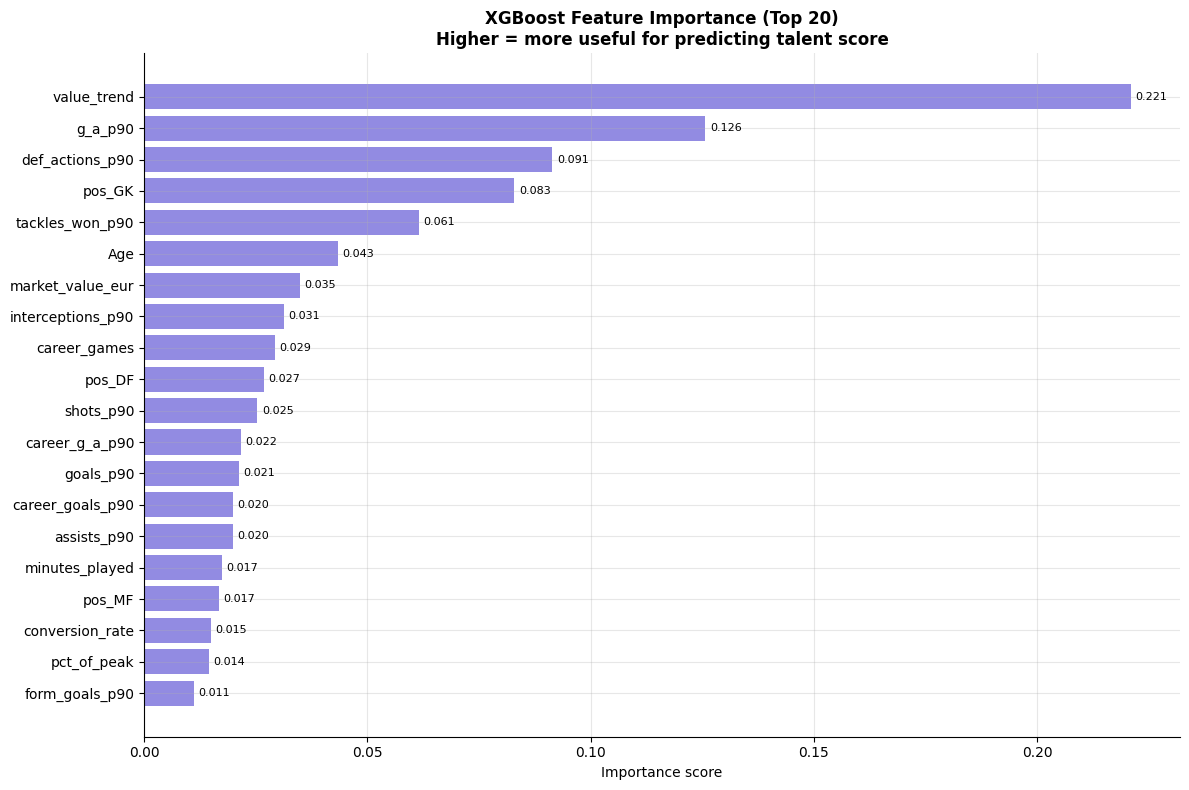

💾 Saved → reports/11_feature_importance.png


In [12]:
# ── XGBoost feature importance ───────────────────────────
importance_df = pd.DataFrame({
    'feature':    available_xgb,
    'importance': model.feature_importances_,
}).sort_values('importance', ascending=False)

print('Top 20 most important features:')
print(importance_df.head(20).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 8))
top_imp = importance_df.head(20)
bars = ax.barh(
    range(len(top_imp)), top_imp['importance'].values,
    color=COLORS[0], alpha=0.85
)
ax.set_yticks(range(len(top_imp)))
ax.set_yticklabels(top_imp['feature'].values, fontsize=10)
ax.set_title('XGBoost Feature Importance (Top 20)\nHigher = more useful for predicting talent score',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Importance score')
ax.invert_yaxis()

for bar, val in zip(bars, top_imp['importance'].values):
    ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=8)

plt.tight_layout()
plt.savefig(REPORTS/'11_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/11_feature_importance.png')

## 🧠 8 — SHAP Explainability (Why did this player score X?)

SHAP values computed
Shape: (4750, 32)


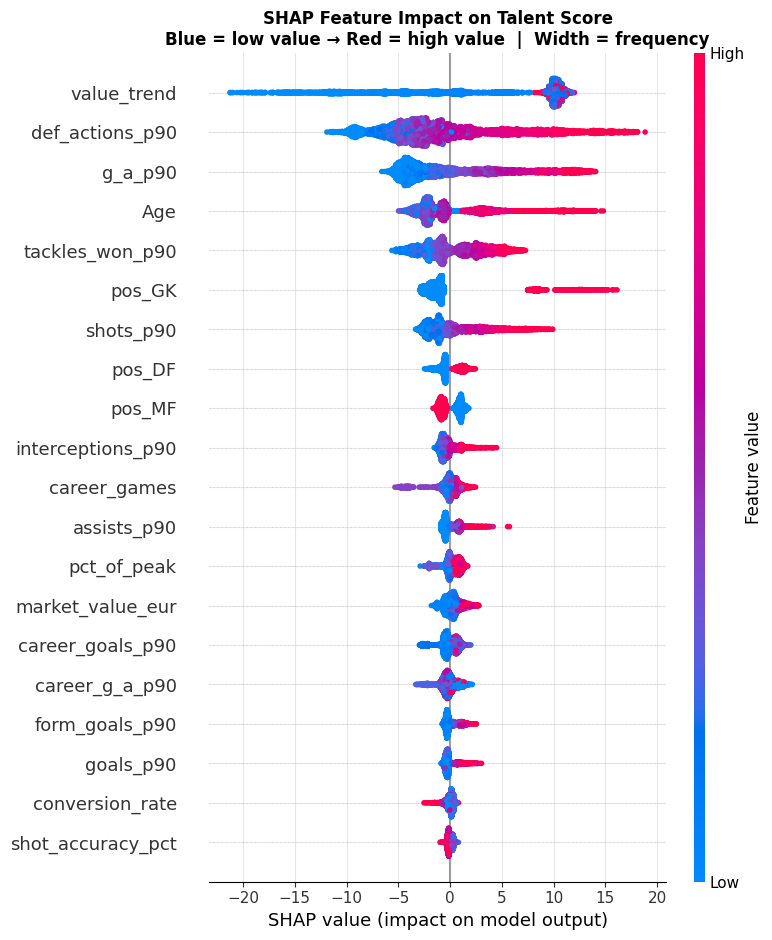

💾 Saved → reports/12_shap_summary.png


In [13]:
if SHAP_AVAILABLE:
    explainer   = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test)

    print('SHAP values computed')
    print(f'Shape: {shap_values.shape}')

    # Summary plot — global feature impact
    fig, ax = plt.subplots(figsize=(12, 8))
    shap.summary_plot(
        shap_values,
        X_test,
        feature_names=available_xgb,
        max_display=20,
        show=False
    )
    plt.title('SHAP Feature Impact on Talent Score\n'
              'Blue = low value → Red = high value  |  Width = frequency',
              fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(REPORTS/'12_shap_summary.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('💾 Saved → reports/12_shap_summary.png')

else:
    print('⚠️  SHAP not available — install with: pip install shap')
    print('   Skipping SHAP plots — model is still fully functional')

In [14]:
if SHAP_AVAILABLE:
    # ── Per-player SHAP explanation ──────────────────────
    # Show why a specific player got their talent score

    def explain_player(player_name):
        """Show SHAP waterfall chart for one player."""
        mask = model_data['Player'].str.contains(player_name, case=False, na=False)
        if not mask.any():
            print(f'❌ {player_name} not found')
            return

        row     = model_data[mask].iloc[0]
        X_row   = row[available_xgb].values.reshape(1, -1).astype(float)
        score   = float(model.predict(X_row)[0])
        sv      = explainer.shap_values(X_row)[0]

        print(f'\n🎯 {row["Player"]} ({row["primary_pos"]}, {row["league"]}, {row["season"]})')
        print(f'   Talent Score: {score:.1f}/100')

        # Top contributing features
        contrib = pd.DataFrame({
            'feature': available_xgb,
            'value':   X_row[0],
            'shap':    sv
        }).sort_values('shap', key=abs, ascending=False).head(10)

        print('   Top factors:')
        for _, r in contrib.iterrows():
            direction = '↑ raises' if r['shap'] > 0 else '↓ lowers'
            print(f'     {direction} score: {r["feature"]:<30} = {r["value"]:>8.3f}  (SHAP: {r["shap"]:+.2f})')

    # Explain known players
    for name in ['Mbappé','Haaland','Lewandowski','Salah']:
        explain_player(name)


🎯 Kylian Mbappé (Forward, Ligue1, 2022-2023)
   Talent Score: 75.9/100
   Top factors:
     ↑ raises score: g_a_p90                        =    1.086  (SHAP: +12.89)
     ↑ raises score: value_trend                    = 4000.000  (SHAP: +9.25)
     ↑ raises score: shots_p90                      =    4.791  (SHAP: +7.01)
     ↓ lowers score: def_actions_p90                =    0.319  (SHAP: -4.39)
     ↓ lowers score: tackles_won_p90                =    0.128  (SHAP: -3.16)
     ↓ lowers score: Age                            =   23.000  (SHAP: -2.16)
     ↑ raises score: form_goals_p90                 =    1.152  (SHAP: +1.92)
     ↑ raises score: market_value_eur               = 200000000.000  (SHAP: +1.79)
     ↑ raises score: career_g_a_p90                 =    1.218  (SHAP: +1.43)
     ↓ lowers score: pos_GK                         =    0.000  (SHAP: -1.24)

🎯 Erling Haaland (Forward, EPL, 2024-2025)
   Talent Score: 72.1/100
   Top factors:
     ↑ raises score: g_a_p90            

## 🎯 9 — Apply Scores to All Players

In [15]:
# ── Apply model to ALL player-season rows ────────────────
X_all = model_data[available_xgb].values.astype(float)
model_data['predicted_talent'] = model.predict(X_all).round(1)

# Clip to 0–100
model_data['predicted_talent'] = model_data['predicted_talent'].clip(0, 100)

# ── Best season per player ────────────────────────────────
SEASON_ORDER = {
    '2020-2021':1,'2021-2022':2,'2022-2023':3,'2023-2024':4,'2024-2025':5
}
model_data['season_rank'] = model_data['season'].map(SEASON_ORDER).fillna(0)

wanted = ['Player','primary_pos','Squad','league','season','Age',
             'predicted_talent','talent_score','goals_p90','assists_p90',
             'market_value_eur','value_efficiency']
wanted = [c for c in wanted if c in model_data.columns]
latest_talent = (
    model_data.sort_values('season_rank', ascending=False)
    .drop_duplicates('Player', keep='first')
    [wanted]
    .sort_values('predicted_talent', ascending=False)
    .reset_index(drop=True)
)

print('TOP 30 TALENT SCORES (latest season per player):')
print(latest_talent.head(30).to_string(index=False))

# Talent labels
def talent_label(score):
    if score >= 85: return 'Elite'
    if score >= 70: return 'World Class'
    if score >= 55: return 'Top Player'
    if score >= 40: return 'Good'
    if score >= 25: return 'Average'
    return 'Developing'

latest_talent['talent_label'] = latest_talent['predicted_talent'].apply(talent_label)
print('\nTalent label distribution:')
print(latest_talent['talent_label'].value_counts().to_string())

TOP 30 TALENT SCORES (latest season per player):
                Player primary_pos               Squad     league    season    Age  predicted_talent  talent_score  goals_p90  assists_p90  market_value_eur  value_efficiency
      Francis Coquelin  Midfielder              Nantes     Ligue1 2024-2025 33.000            90.800        90.000      0.402        0.402        800000.000             2.500
          Matt Ritchie    Defender    Newcastle United        EPL 2023-2024 33.000            89.000       100.000      0.703        0.000       1000000.000             1.000
      Marko Arnautović     Forward               Inter     SerieA 2024-2025 35.000            88.600        92.700      0.656        0.328       2500000.000             2.400
        Marten de Roon  Midfielder            Atalanta     SerieA 2024-2025 33.000            88.200        85.300      0.118        0.118       3500000.000             2.286
            Marco Reus  Midfielder            Dortmund Bundesliga 2023-2024 

In [16]:
# ── Hidden gem finder ─────────────────────────────────────
# High talent score + low market value = undervalued player
print('='*60)
print('  💎 HIDDEN GEMS: High Talent + Low Market Value')
print('  (Talent Score > 65 + Market Value < €15M)')
print('='*60)

gems = latest_talent[
    (latest_talent['predicted_talent'] >= 65) &
    (pd.to_numeric(latest_talent['market_value_eur'], errors='coerce') < 15_000_000)
].sort_values('predicted_talent', ascending=False).head(20)

if not gems.empty:
    gems_display = gems.copy()
    gems_display['value_M'] = (pd.to_numeric(gems_display['market_value_eur'], errors='coerce') / 1e6).round(1)
    print(gems_display[['Player','Age','primary_pos','Squad','league',
                          'predicted_talent','value_M','goals_p90']].to_string(index=False))
else:
    print('No gems found with these thresholds — try adjusting criteria')

# ── Rising stars: Young + High talent + Rising value ─────
print()
print('='*60)
print('  🌟 RISING STARS: U23 + Talent > 60 + Value Trending Up')
print('='*60)
stars = model_data[
    (pd.to_numeric(model_data['Age'], errors='coerce') <= 23) &
    (model_data['predicted_talent'] >= 60) &
    (pd.to_numeric(model_data['value_trend'], errors='coerce') > 1.5)
].sort_values('predicted_talent', ascending=False)

stars_latest = (
    stars.sort_values('season_rank', ascending=False)
    .drop_duplicates('Player', keep='first')
    .head(15)
)

if not stars_latest.empty:
    print(stars_latest[['Player','Age','primary_pos','league','season',
                          'predicted_talent','value_trend','goals_p90']].to_string(index=False))

  💎 HIDDEN GEMS: High Talent + Low Market Value
  (Talent Score > 65 + Market Value < €15M)
            Player    Age primary_pos            Squad     league  predicted_talent  value_M  goals_p90
  Francis Coquelin 33.000  Midfielder           Nantes     Ligue1            90.800    0.800      0.402
      Matt Ritchie 33.000    Defender Newcastle United        EPL            89.000    1.000      0.703
  Marko Arnautović 35.000     Forward            Inter     SerieA            88.600    2.500      0.656
    Marten de Roon 33.000  Midfielder         Atalanta     SerieA            88.200    3.500      0.118
        Marco Reus 34.000  Midfielder         Dortmund Bundesliga            87.700    1.800      0.337
    Arthur Masuaku 27.000  Midfielder  West Ham United        EPL            87.500    2.500      0.138
  Patrick Herrmann 31.000     Forward         Gladbach Bundesliga            86.600    1.000      0.549
      Mats Hummels 35.000    Defender             Roma     SerieA           

## 📊 10 — Validation Charts

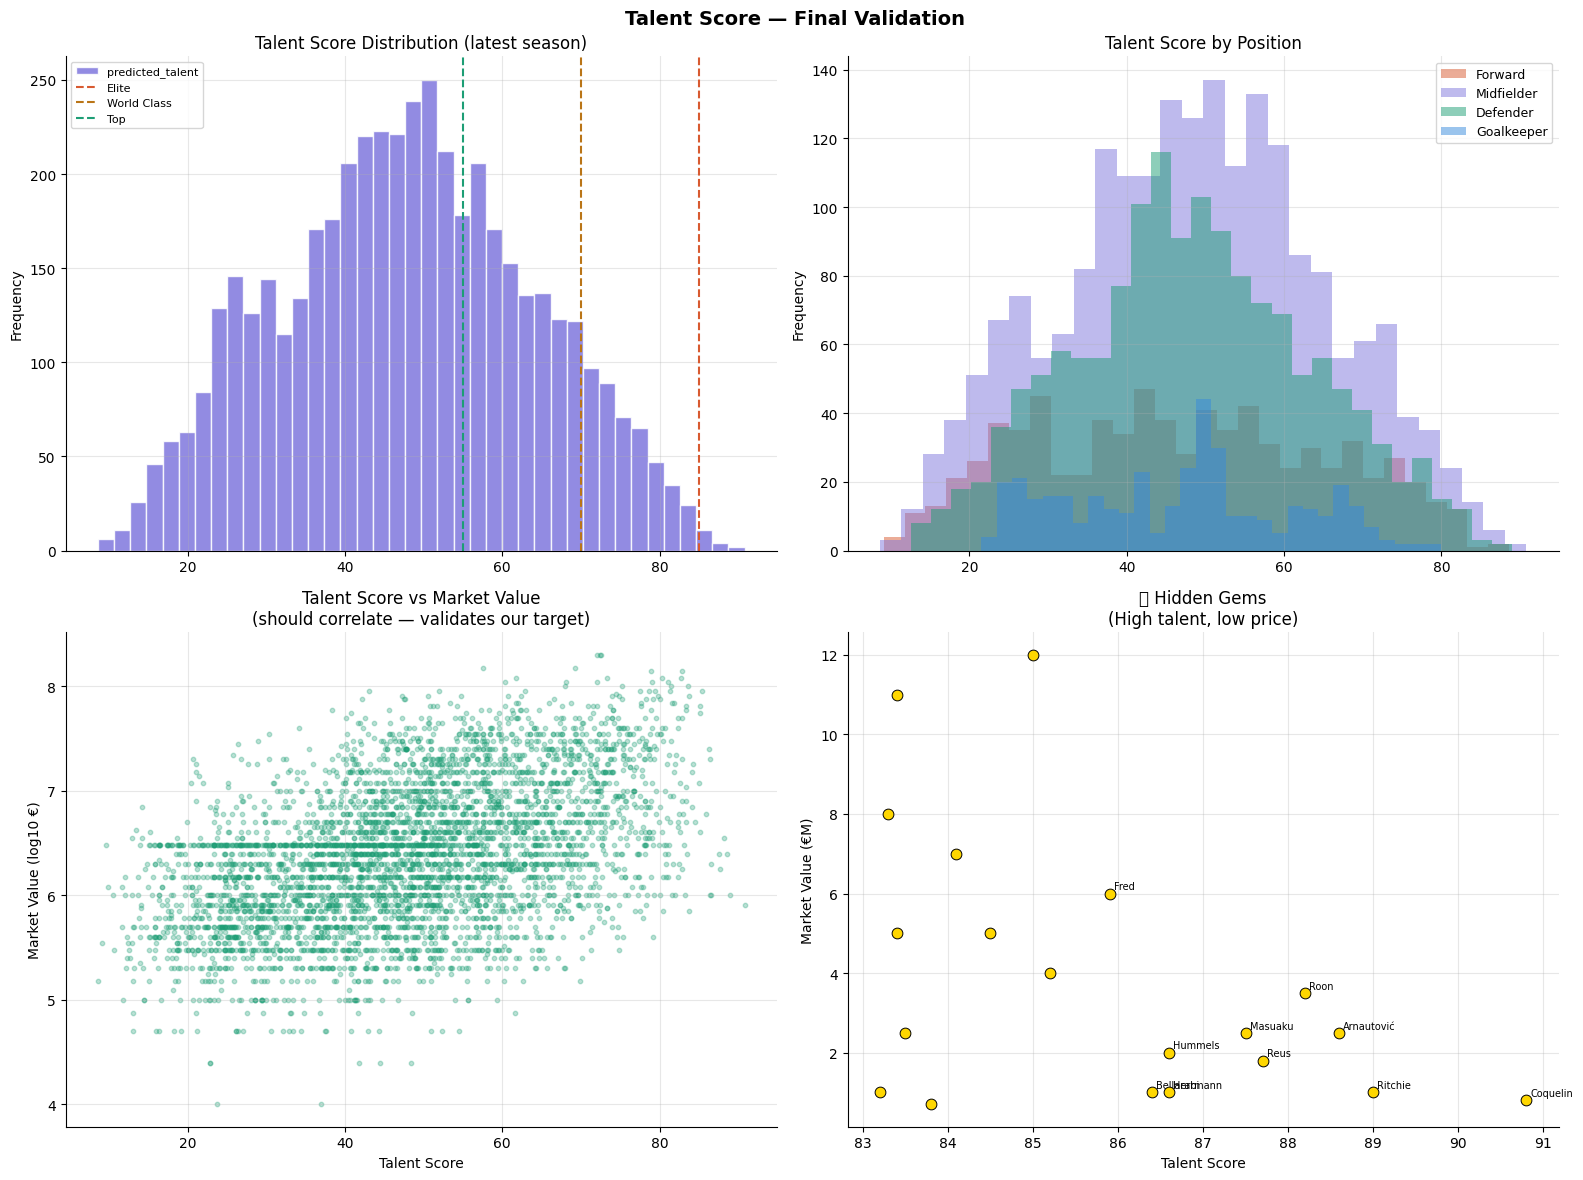

💾 Saved → reports/13_talent_validation.png


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Talent Score — Final Validation', fontsize=14, fontweight='bold')

# Score distribution
ax = axes[0,0]
latest_talent['predicted_talent'].plot.hist(
    bins=40, ax=ax, color=COLORS[0], alpha=0.85, edgecolor='white')
for threshold, label, color in [
    (85,'Elite','#D85A30'),(70,'World Class','#BA7517'),
    (55,'Top','#1D9E75')
]:
    ax.axvline(threshold, color=color, linestyle='--', linewidth=1.5, label=label)
ax.set_title('Talent Score Distribution (latest season)')
ax.legend(fontsize=8)

# Score by position
ax = axes[0,1]
for pos, color in [('Forward',COLORS[2]),('Midfielder',COLORS[0]),
                    ('Defender',COLORS[1]),('Goalkeeper',COLORS[3])]:
    mask = latest_talent['primary_pos'] == pos
    if mask.sum() > 0:
        latest_talent[mask]['predicted_talent'].plot.hist(
            bins=30, ax=ax, alpha=0.5, color=color, label=pos, edgecolor='none')
ax.set_title('Talent Score by Position')
ax.legend(fontsize=9)

# Talent vs market value
ax = axes[1,0]
val = pd.to_numeric(latest_talent['market_value_eur'], errors='coerce')
mask = val.notna() & (val > 0)
ax.scatter(
    latest_talent[mask]['predicted_talent'],
    np.log10(val[mask]),
    alpha=0.3, s=10, color=COLORS[1]
)
ax.set_xlabel('Talent Score')
ax.set_ylabel('Market Value (log10 €)')
ax.set_title('Talent Score vs Market Value\n(should correlate — validates our target)')

# Hidden gems highlighted
ax = axes[1,1]
if not gems.empty and 'market_value_eur' in gems.columns:
    gem_val = pd.to_numeric(gems['market_value_eur'], errors='coerce')
    ax.scatter(
        gems['predicted_talent'], gem_val / 1e6,
        s=60, color='gold', edgecolors='black', linewidth=0.7, zorder=5
    )
    for _, row in gems.head(10).iterrows():
        v = pd.to_numeric(row['market_value_eur'], errors='coerce') / 1e6
        if not np.isnan(v):
            ax.annotate(row['Player'].split()[-1],
                        (row['predicted_talent'], v),
                        xytext=(3,3), textcoords='offset points', fontsize=7)
ax.set_xlabel('Talent Score')
ax.set_ylabel('Market Value (€M)')
ax.set_title('💎 Hidden Gems\n(High talent, low price)')

plt.tight_layout()
plt.savefig(REPORTS/'13_talent_validation.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/13_talent_validation.png')

## 💾 11 — Save Model & Scores

In [18]:
# ── Save XGBoost model ───────────────────────────────────
with open(PROCESSED / 'xgb_talent_model.pkl', 'wb') as f:
    pickle.dump(model, f)

# ── Save feature list ────────────────────────────────────
with open(PROCESSED / 'talent_features.pkl', 'wb') as f:
    pickle.dump(available_xgb, f)

# ── Save talent scores per player (latest season) ────────
export_cols = ['Player','primary_pos','Squad','league','season','Age',
               'predicted_talent','talent_label','goals_p90','assists_p90',
               'market_value_eur','value_efficiency']
export_cols = [c for c in export_cols if c in latest_talent.columns]
talent_export = latest_talent[export_cols].copy()
talent_export.to_csv(PROCESSED / 'talent_scores.csv', index=False)

# ── Save all-season scores (for historical analysis) ─────
all_season_cols = ['Player','primary_pos','Squad','league','season','Age',
                   'predicted_talent','talent_score']
all_season_cols = [c for c in all_season_cols if c in model_data.columns]
model_data[all_season_cols].to_csv(PROCESSED / 'talent_scores_all_seasons.csv', index=False)

print('✅ Saved:')
for f in ['xgb_talent_model.pkl','talent_features.pkl',
           'talent_scores.csv','talent_scores_all_seasons.csv']:
    p = PROCESSED / f
    print(f'  📁 {f:<40} {p.stat().st_size/1024:.1f} KB')

✅ Saved:
  📁 xgb_talent_model.pkl                     496.4 KB
  📁 talent_features.pkl                      0.5 KB
  📁 talent_scores.csv                        434.2 KB
  📁 talent_scores_all_seasons.csv            758.2 KB


## 🖨️ 12 — Summary Print for Claude

In [19]:
top5_per_pos = {}
for pos in ['Forward','Midfielder','Defender','Goalkeeper']:
    top5 = (
        latest_talent[latest_talent['primary_pos']==pos]
        .head(5)['Player'].tolist()
    )
    top5_per_pos[pos] = top5

summary = {
    'model': {
        'name':            'XGBoost Regressor',
        'n_estimators':    xgb_params['n_estimators'],
        'max_depth':       xgb_params['max_depth'],
        'n_features':      len(available_xgb),
        'feature_list':    available_xgb,
        'n_players':       len(latest_talent),
    },
    'target_construction': {
        'signal_1_performance':   f'{W1*100:.0f}% — per-90 performance percentile within age+position bucket',
        'signal_2_value_trend':   f'{W2*100:.0f}% — market value trajectory percentile',
        'signal_3_trajectory':    f'{W3*100:.0f}% — season-over-season improvement slope',
        'bucket_strategy':        'Percentile computed within age_group + primary_pos',
    },
    'evaluation': {
        'test_rmse':       round(test_rmse, 2),
        'test_mae':        round(test_mae, 2),
        'test_r2':         round(test_r2, 4),
        'cv_r2_mean':      round(float(cv_scores.mean()), 4),
        'cv_r2_std':       round(float(cv_scores.std()), 4),
        'overfit_gap':     round(float(train_r2 - test_r2), 4),
    },
    'talent_labels': {
        'Elite (85–100)':      int((latest_talent['predicted_talent']>=85).sum()),
        'World Class (70–85)': int(((latest_talent['predicted_talent']>=70) & (latest_talent['predicted_talent']<85)).sum()),
        'Top Player (55–70)':  int(((latest_talent['predicted_talent']>=55) & (latest_talent['predicted_talent']<70)).sum()),
        'Good (40–55)':        int(((latest_talent['predicted_talent']>=40) & (latest_talent['predicted_talent']<55)).sum()),
        'Average (25–40)':     int(((latest_talent['predicted_talent']>=25) & (latest_talent['predicted_talent']<40)).sum()),
        'Developing (0–25)':   int((latest_talent['predicted_talent']<25).sum()),
    },
    'top5_by_position':     top5_per_pos,
    'top_importance_features': importance_df.head(10)['feature'].tolist(),
    'hidden_gems_found':    len(gems),
    'saved_artifacts': [
        'xgb_talent_model.pkl',
        'talent_features.pkl',
        'talent_scores.csv',
        'talent_scores_all_seasons.csv',
    ],
    'next_notebook': 'notebook 06 — Model 3: K-Means Style Clustering',
}

print('='*60)
print('  NB05 COMPLETE — XGBOOST TALENT SCORE')
print('='*60)
print(json.dumps(summary, indent=2, default=str))

with open(PROCESSED/'nb05_summary.json','w') as f:
    json.dump(summary, f, indent=2, default=str)

print(f"""
{'='*60}
  TALENT SCORE READY:
  Players scored:   {len(latest_talent):,}
  Test R²:          {test_r2:.4f}
  Test RMSE:        {test_rmse:.2f} points
  Hidden gems:      {len(gems):,} players
  Top features:     {importance_df.head(5)['feature'].tolist()}
  → NEXT: notebook 06 — K-Means Style Clustering
{'='*60}
""")

  NB05 COMPLETE — XGBOOST TALENT SCORE
{
  "model": {
    "name": "XGBoost Regressor",
    "n_estimators": 300,
    "max_depth": 4,
    "n_features": 32,
    "feature_list": [
      "Age",
      "pos_FW",
      "pos_MF",
      "pos_DF",
      "pos_GK",
      "is_versatile",
      "games_played",
      "starts",
      "minutes_played",
      "availability_pct",
      "goals_p90",
      "assists_p90",
      "g_a_p90",
      "shots_p90",
      "shot_accuracy_pct",
      "conversion_rate",
      "finishing_quality",
      "tackles_won_p90",
      "interceptions_p90",
      "def_actions_p90",
      "yellow_p90",
      "red_p90",
      "market_value_eur",
      "value_trend",
      "pct_of_peak",
      "career_games",
      "career_goals_p90",
      "career_g_a_p90",
      "form_games",
      "form_goals_p90",
      "injury_risk_score",
      "total_days_out"
    ],
    "n_players": 4677
  },
  "target_construction": {
    "signal_1_performance": "40% \u2014 per-90 performance percentile wit